# Exerciţiu laborator 4
## Reţele Markov

Considerăm o reţea de Markov de dimensiune mică care descrie distribuţia probabilităţilor pentru 5 variabile discrete binare (cu valorile 0 şi 1): $A_1$, $A_2$, $A_3$, $A_4$ şi $A_5$. Relaţiile de independenţă condiţionată dintre aceste variabile sunt descrise de următoarele conexiuni: $A_1$ este conectat cu $A_2$ şi $A_3$, $A_2$ este conectat cu $A_4$ şi $A_5$, $A_3$ este conectat cu $A_4$, iar $A_4$ este conectat cu $A_5$.

Se cunoaşte următoarea distribuţie a energiei pentru clicile maximale ale modelului:

$$\phi_C(a_C) = e^{\beta \sum_{i, j \in C,\ i<j} a_i a_j}.$$



a) Vizualizaţi în pyAgrum graful reţelei Markov, iar apoi determinaţi clicile modelului.


{1<A1>,2<A2>,3<A3>,4<A4>,5<A5>} , {1--3,2--5,4--5,1--2,2--4,3--4}


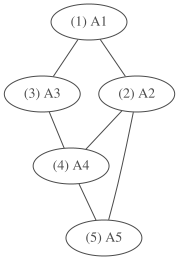

In [13]:
import pyagrum
import math
import pyagrum.lib.notebook as ntb

markov = pyagrum.UndiGraph()
for i in range(1, 6) :
  markov.addNodeWithId(i)
  markov.setName(i, f'A{i}')
markov.addEdge(1, 2)
markov.addEdge(1, 3)
markov.addEdge(2, 4)
markov.addEdge(2, 5)
markov.addEdge(3, 4)
markov.addEdge(4, 5)

print(markov)
ntb.show(markov)

Clicile maximale sunt:
    - A1 A2
    - A1 A3
    - A3 A4
    - A2 A4 A5


b) Determinaţi probabilitatea comună a celor 5 variabile şi deduceţi stările de probabilitate maximă pentru acestea.


In [15]:
clici = [[0, 1], [0, 2], [2, 3], [1, 3, 4]]

Z = 0
beta = 1
for i in range(0, 32):
  output = [i & 1, (i & 2) // 2, (i & 4) // 4, (i & 8) // 8, (i & 16) // 16]

  potential = 0
  for clica in clici:
    for i in clica:
      for j in clica:
        if i < j:
          potential += output[i] * output[j]
  Z += math.exp(beta * potential)
for i in range(0, 32):
  output = [i & 1, (i & 2) // 2, (i & 4) // 4, (i & 8) // 8, (i & 16) // 16]

  potential = 0
  for clica in clici:
    for i in clica:
      for j in clica:
        if i < j:
          potential += output[i] * output[j]
  print(f'P({output}) = {math.exp(beta * potential) / Z}')
  # e^beta*suma_potentialelor

P([0, 0, 0, 0, 0]) = 0.001415871611573323
P([1, 0, 0, 0, 0]) = 0.001415871611573323
P([0, 1, 0, 0, 0]) = 0.001415871611573323
P([1, 1, 0, 0, 0]) = 0.003848738073170787
P([0, 0, 1, 0, 0]) = 0.001415871611573323
P([1, 0, 1, 0, 0]) = 0.003848738073170787
P([0, 1, 1, 0, 0]) = 0.001415871611573323
P([1, 1, 1, 0, 0]) = 0.01046195476679863
P([0, 0, 0, 1, 0]) = 0.001415871611573323
P([1, 0, 0, 1, 0]) = 0.001415871611573323
P([0, 1, 0, 1, 0]) = 0.003848738073170787
P([1, 1, 0, 1, 0]) = 0.01046195476679863
P([0, 0, 1, 1, 0]) = 0.003848738073170787
P([1, 0, 1, 1, 0]) = 0.01046195476679863
P([0, 1, 1, 1, 0]) = 0.01046195476679863
P([1, 1, 1, 1, 0]) = 0.07730397067635
P([0, 0, 0, 0, 1]) = 0.001415871611573323
P([1, 0, 0, 0, 1]) = 0.001415871611573323
P([0, 1, 0, 0, 1]) = 0.003848738073170787
P([1, 1, 0, 0, 1]) = 0.01046195476679863
P([0, 0, 1, 0, 1]) = 0.001415871611573323
P([1, 0, 1, 0, 1]) = 0.003848738073170787
P([0, 1, 1, 0, 1]) = 0.003848738073170787
P([1, 1, 1, 0, 1]) = 0.028438541532749207
P

pentru beta pozitiv, probabilitatea maxima este cand toate sunt 1


c) Explicaţi cum aţi modifica funcţiile de potenţial pentru a modela modelul Ising, în care sunt favorizate perechile de vecini care au aceeaşi valoare.

in loc de ai * aj as pune ~(ai \^ aj) = (1 - (ai + aj - 2 * ai * aj))